# Fourier lecture plots

Self-contained, deterministic figures for CS138. All functions, coefficients,
and plotting helpers are defined here; no external data or helper files are
read. The palette uses navy `#162443`, gold `#e3b52d`, and teal `#257f9b` on
white backgrounds. Every figure is saved as an SVG and a PNG preview.

**Run:** execute all cells from this notebook's `notebooks` directory, or
from the project root. Files go to `assets/plots` in the project root,
which is `../assets/plots` relative to the notebook.

## Conventions

The house convention uses full period $2L$ on $[-L,L]$, with
$\omega_0=\pi/L$. These plots use the normalized case $L=\pi$,
so $-\pi\leq\theta\leq\pi$. We use the **mean-as-constant-term convention**

\[
f(\theta)=a_0+\sum_{n=1}^{\infty}
\bigl(a_n\cos n\theta+b_n\sin n\theta\bigr).
\]

Thus $a_0$ is the mean, not twice the mean. For complex Fourier series,
analysis uses $e^{-in\theta}$ and synthesis uses $e^{in\theta}$:

\[
C_n=\frac{1}{2\pi}\int_{-\pi}^{\pi}f(\theta)e^{-in\theta}\,d\theta,
\qquad C_0=a_0,\qquad C_n=\frac{a_n-ib_n}{2}\quad(n>0).
\]

On a general interval $[-L,L]$, replace $n\theta$ by $n\pi x/L$
and $1/(2\pi)$ by $1/(2L)$ in the coefficient formula.

The Fourier transform uses
$\widehat g(\omega)=\int_{\mathbb R}g(x)e^{-i\omega x}\,dx$ and
$g(x)=(2\pi)^{-1}\int_{\mathbb R}\widehat g(\omega)e^{i\omega x}\,d\omega$.
All checks at the end use the formulas actually plotted.


In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, FancyArrowPatch
from matplotlib.path import Path as CurvePath
import numpy as np
import scipy
from scipy.integrate import quad


NAVY = "#162443"
GOLD = "#e3b52d"
TEAL = "#257f9b"
MUTED = "#657184"
GRID = "#d9dee7"
PI = np.pi

working_dir = Path.cwd().resolve()
if working_dir.name == "notebooks":
    project_dir = working_dir.parent
else:
    project_dir = working_dir
PLOT_DIR = project_dir / "assets" / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
CREATED_PLOTS = []

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 18,
    "axes.titlesize": 22,
    "axes.labelsize": 19,
    "axes.labelcolor": NAVY,
    "text.color": NAVY,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.edgecolor": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "medium",
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "mathtext.fontset": "dejavusans",
    "lines.linewidth": 3.0,
    "legend.frameon": False,
    "legend.fontsize": 16,
    "svg.fonttype": "path",
    "svg.hashsalt": "cs138-fourier-plots",
})


def export_plot(fig, stem):
    """Save a deterministic SVG and a notebook-friendly PNG preview."""
    svg_path = PLOT_DIR / f"{stem}.svg"
    png_path = PLOT_DIR / f"{stem}.png"
    fig.savefig(
        svg_path,
        bbox_inches="tight",
        pad_inches=0.16,
        metadata={"Date": None, "Creator": "CS138 Fourier notebook"},
    )
    fig.savefig(png_path, dpi=160, bbox_inches="tight", pad_inches=0.16)
    CREATED_PLOTS.append((svg_path, png_path))
    print(f"Saved {svg_path.name} and {png_path.name}")
    plt.show()
    plt.close(fig)


def periodic_axis(ax, ylim=(-1.15, 1.15)):
    """Use the same coordinate ticks for normalized periodic plots."""
    ax.set_xlim(-PI, PI)
    ax.set_ylim(*ylim)
    ax.set_xticks([-PI, 0, PI], [r"$-\pi$", "0", r"$\pi$"])
    ax.axhline(0, color=GRID, linewidth=1, zorder=0)
    ax.tick_params(length=4)
    ax.set_xlabel(r"$\theta$")


def complex_plane(ax, xlim=(-1.3, 1.4), ylim=(-1.3, 1.4)):
    """Label a complex output plane rather than a function graph."""
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.axhline(0, color=GRID, linewidth=1, zorder=0)
    ax.axvline(0, color=GRID, linewidth=1, zorder=0)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    width = xlim[1] - xlim[0]
    height = ylim[1] - ylim[0]
    ax.text(
        xlim[1] - 0.01 * width,
        -0.06 * height,
        r"$\mathrm{Re}\,z$",
        ha="right",
        va="top",
        color=MUTED,
        fontsize=16,
    )
    ax.text(
        0.045 * width,
        ylim[1] - 0.02 * height,
        r"$\mathrm{Im}\,z$",
        va="top",
        color=MUTED,
        fontsize=16,
    )


def draw_vector(ax, start, end, color, linewidth=3.0):
    """Draw an exact displacement vector in the complex plane."""
    ax.add_patch(FancyArrowPatch(
        start,
        end,
        arrowstyle="-|>",
        mutation_scale=19,
        linewidth=linewidth,
        color=color,
        shrinkA=0,
        shrinkB=0,
        zorder=5,
    ))


def orbit_arrow(ax, start_angle, direction, color):
    """Draw an oriented short arc on the unit circle."""
    angles = np.linspace(start_angle, start_angle + direction * 0.5, 30)
    vertices = np.column_stack((np.cos(angles), np.sin(angles)))
    ax.add_patch(FancyArrowPatch(
        path=CurvePath(vertices),
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=2.8,
        color=color,
        zorder=4,
    ))


print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("SciPy:", scipy.__version__)
print("Export folder:", PLOT_DIR)


NumPy: 2.3.5
Matplotlib: 3.10.8
SciPy: 1.17.0
Export folder: /workspace/scratch/5c4d2a0156e7/fourier-typst/assets/plots


## Shared exact functions

The periodic unit-height tent is

\[
f(\theta)=1-\frac{|\theta|}{\pi},
\quad -\pi\leq\theta\leq\pi,
\]

extended periodically. Its mean is $a_0=1/2$, all sine coefficients vanish,
and $a_n=4/(\pi^2n^2)$ for positive odd $n$, with $a_n=0$ for even $n$.
For $u-u''=f$, each nonconstant cosine coefficient is divided by $1+n^2$.

The tent has corners, but its explicit $O(n^{-2})$ coefficients are
absolutely summable. The filtered solution has $O(n^{-4})$ coefficients;
its series can be differentiated twice uniformly. The numerical residual
check uses finite sums, so no interchange of infinite sums is assumed.


In [2]:
def periodic_tent(theta):
    """Evaluate the unit-height tent with period 2*pi."""
    phase = (np.asarray(theta) + PI) % (2 * PI) - PI
    return 1 - np.abs(phase) / PI


def cosine_coefficient(n):
    """Return the tent coefficient for a positive integer mode."""
    if n < 1 or int(n) != n:
        raise ValueError("n must be a positive integer")
    return 4 / (PI**2 * n**2) if n % 2 else 0.0


def tent_partial_sum(theta, highest_mode):
    """Return the finite cosine expansion including the mean."""
    theta = np.asarray(theta, dtype=float)
    result = np.full_like(theta, 0.5)
    for n in range(1, highest_mode + 1, 2):
        result += cosine_coefficient(n) * np.cos(n * theta)
    return result


def filtered_tent(theta, highest_mode=199, derivative=0):
    """Evaluate the resolvent-filtered tent or its first two derivatives."""
    theta = np.asarray(theta, dtype=float)
    if derivative not in (0, 1, 2):
        raise ValueError("derivative must be 0, 1, or 2")
    result = np.full_like(theta, 0.5 if derivative == 0 else 0.0)
    for n in range(1, highest_mode + 1, 2):
        coefficient = cosine_coefficient(n) / (1 + n**2)
        if derivative == 0:
            result += coefficient * np.cos(n * theta)
        elif derivative == 1:
            result -= n * coefficient * np.sin(n * theta)
        else:
            result -= n**2 * coefficient * np.cos(n * theta)
    return result


def triangular_pulse(x):
    """Evaluate the compact triangle max(1-|x|, 0)."""
    return np.maximum(1 - np.abs(np.asarray(x)), 0.0)


def repeated_pulse(x, period):
    """Periodize the triangle without overlap for period greater than 2."""
    if period <= 2:
        raise ValueError("period must exceed the pulse width 2")
    centered = (np.asarray(x) + period / 2) % period - period / 2
    return triangular_pulse(centered)


def pulse_transform(omega):
    """Evaluate the exact transform, including its limit 1 at omega=0."""
    return np.sinc(np.asarray(omega) / (2 * PI))**2


## 1. Periodic modes and endpoint matching

For $y''+\lambda y=0$ with periodic values and slopes on $[-\pi,\pi]$,
the constant mode has $\lambda=0$, and each $n\geq1$ gives the two real
modes $\cos n\theta$ and $\sin n\theta$ with $\lambda=n^2$.
Matching endpoint markers indicate equal values; the numerical check
below also verifies the endpoint slopes.


Saved 01-periodic-modes.svg and 01-periodic-modes.png


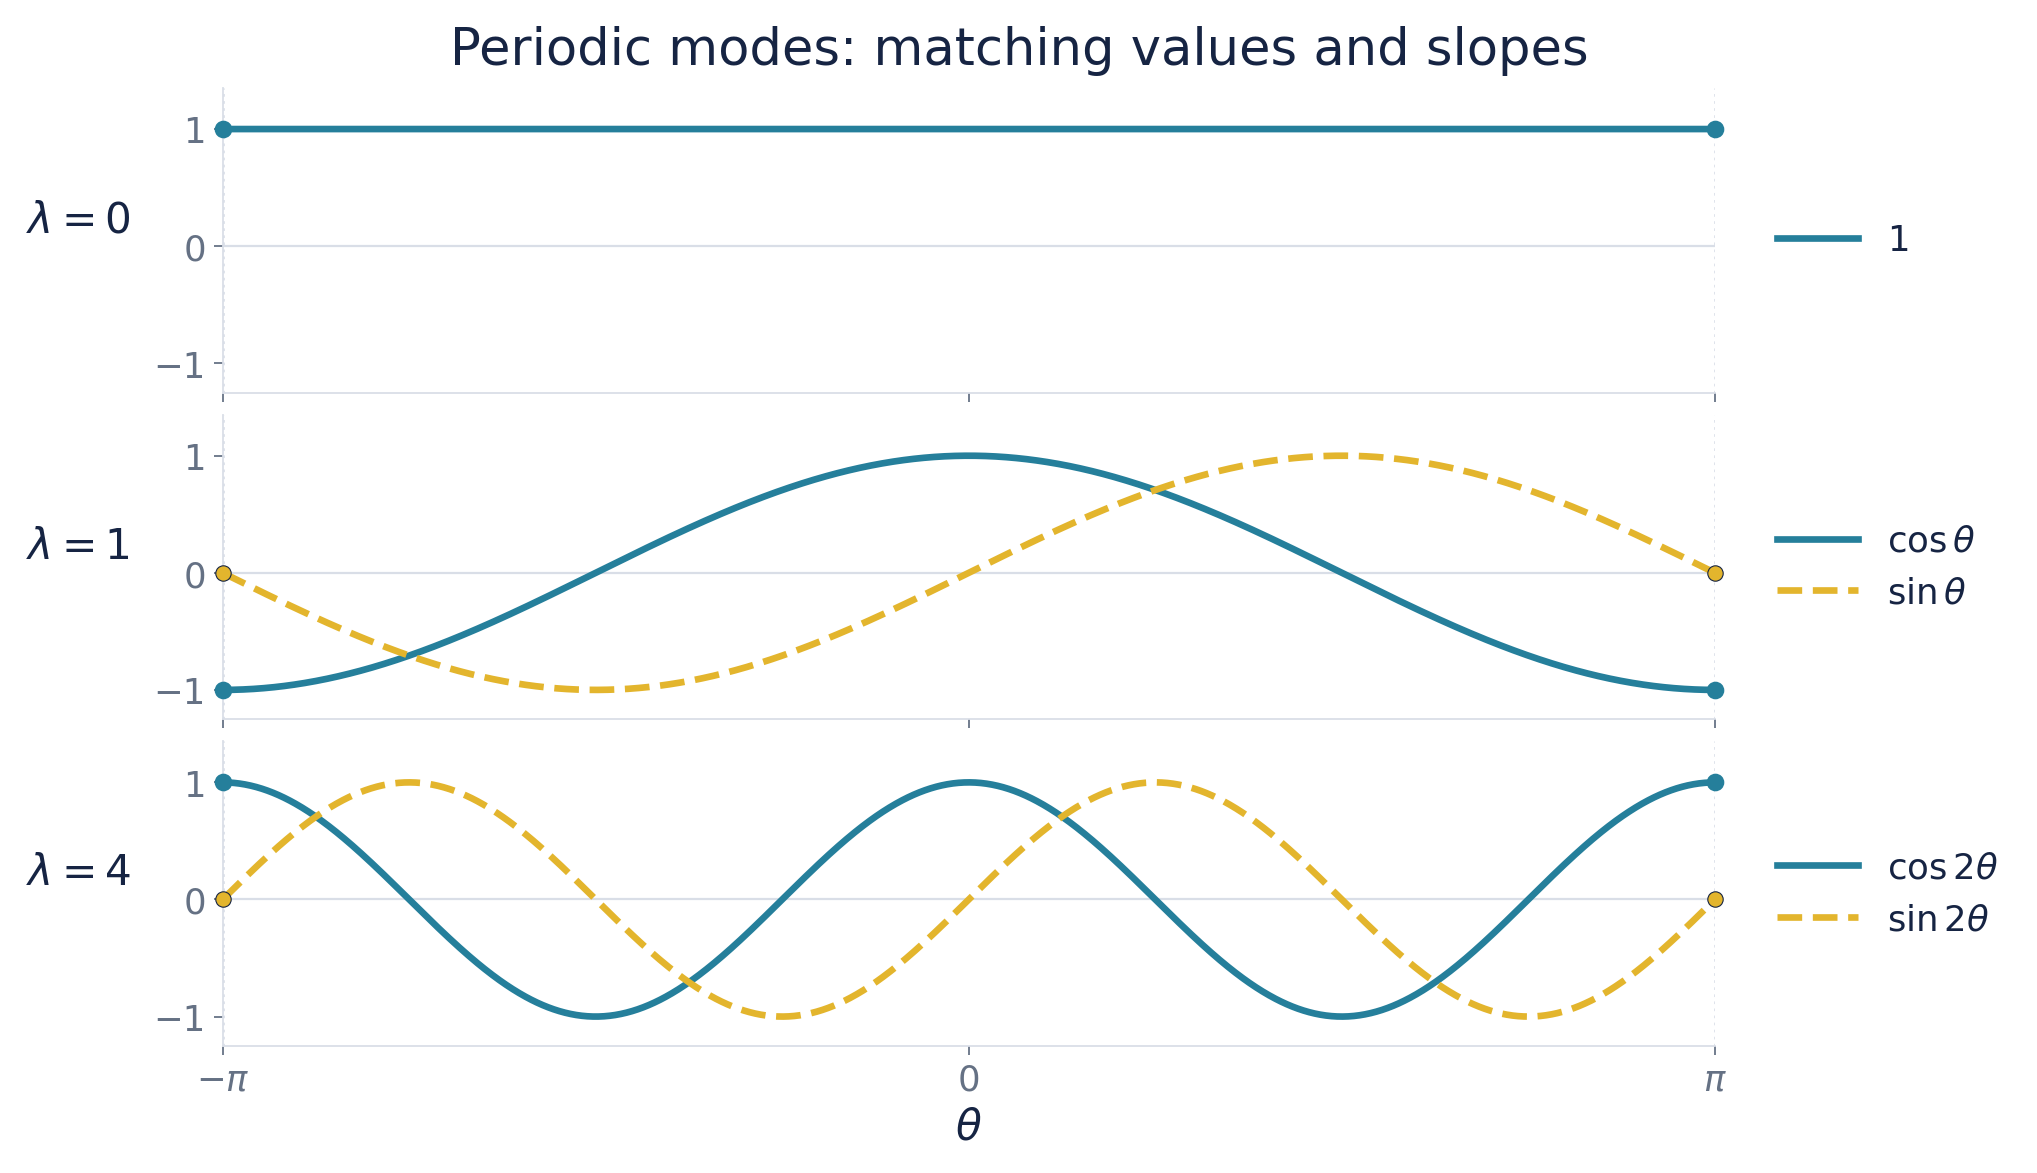

In [3]:
theta = np.linspace(-PI, PI, 1601)
fig, axes = plt.subplots(3, 1, figsize=(12.5, 7.1), layout="constrained")

for n, ax in enumerate(axes):
    periodic_axis(ax, ylim=(-1.25, 1.35))
    ax.set_yticks([-1, 0, 1])
    ax.axvline(-PI, color=GRID, linewidth=1.2, linestyle=":")
    ax.axvline(PI, color=GRID, linewidth=1.2, linestyle=":")
    if n == 0:
        ax.plot(theta, np.ones_like(theta), color=TEAL, label="$1$")
        ax.scatter(
            [-PI, PI], [1, 1], color=TEAL, s=48,
            clip_on=False, zorder=5,
        )
    else:
        cosine_label = r"$\cos\theta$" if n == 1 else r"$\cos2\theta$"
        sine_label = r"$\sin\theta$" if n == 1 else r"$\sin2\theta$"
        ax.plot(theta, np.cos(n * theta), color=TEAL, label=cosine_label)
        ax.plot(
            theta, np.sin(n * theta), color=GOLD,
            linestyle="--", label=sine_label,
        )
        ax.scatter(
            [-PI, PI], [(-1)**n, (-1)**n], color=TEAL, s=48,
            clip_on=False, zorder=5,
        )
        ax.scatter(
            [-PI, PI], [0, 0], color=GOLD, edgecolor=NAVY,
            linewidth=0.5, s=48, clip_on=False, zorder=5,
        )
    ax.set_ylabel(rf"$\lambda={n**2}$", rotation=0, labelpad=34)
    ax.legend(
        loc="center left", bbox_to_anchor=(1.02, 0.5),
        handlelength=2.3,
    )
    if n < 2:
        ax.set_xlabel("")
        ax.set_xticklabels([])

fig.suptitle("Periodic modes: matching values and slopes", fontsize=23)
export_plot(fig, "01-periodic-modes")


## 2. Complex output and conjugate rotations

Here $\theta$ is a real input. The diagrams are complex **output planes**,
not plots of output versus input. At $\theta=\pi/3$,
$e^{i\theta}=1/2+i\sqrt3/2$.
Adding $(1/2)e^{i\theta}$ and $(1/2)e^{-i\theta}$ tip-to-tail cancels
their imaginary components and gives $\cos\theta=1/2$.
Standalone exports `02a` and `02b` allow these ideas to be introduced
on separate slides before showing the combined figure.


Saved 02-complex-rotations.svg and 02-complex-rotations.png
Saved 02a-unit-circle.svg and 02a-unit-circle.png
Saved 02b-conjugate-pair.svg and 02b-conjugate-pair.png


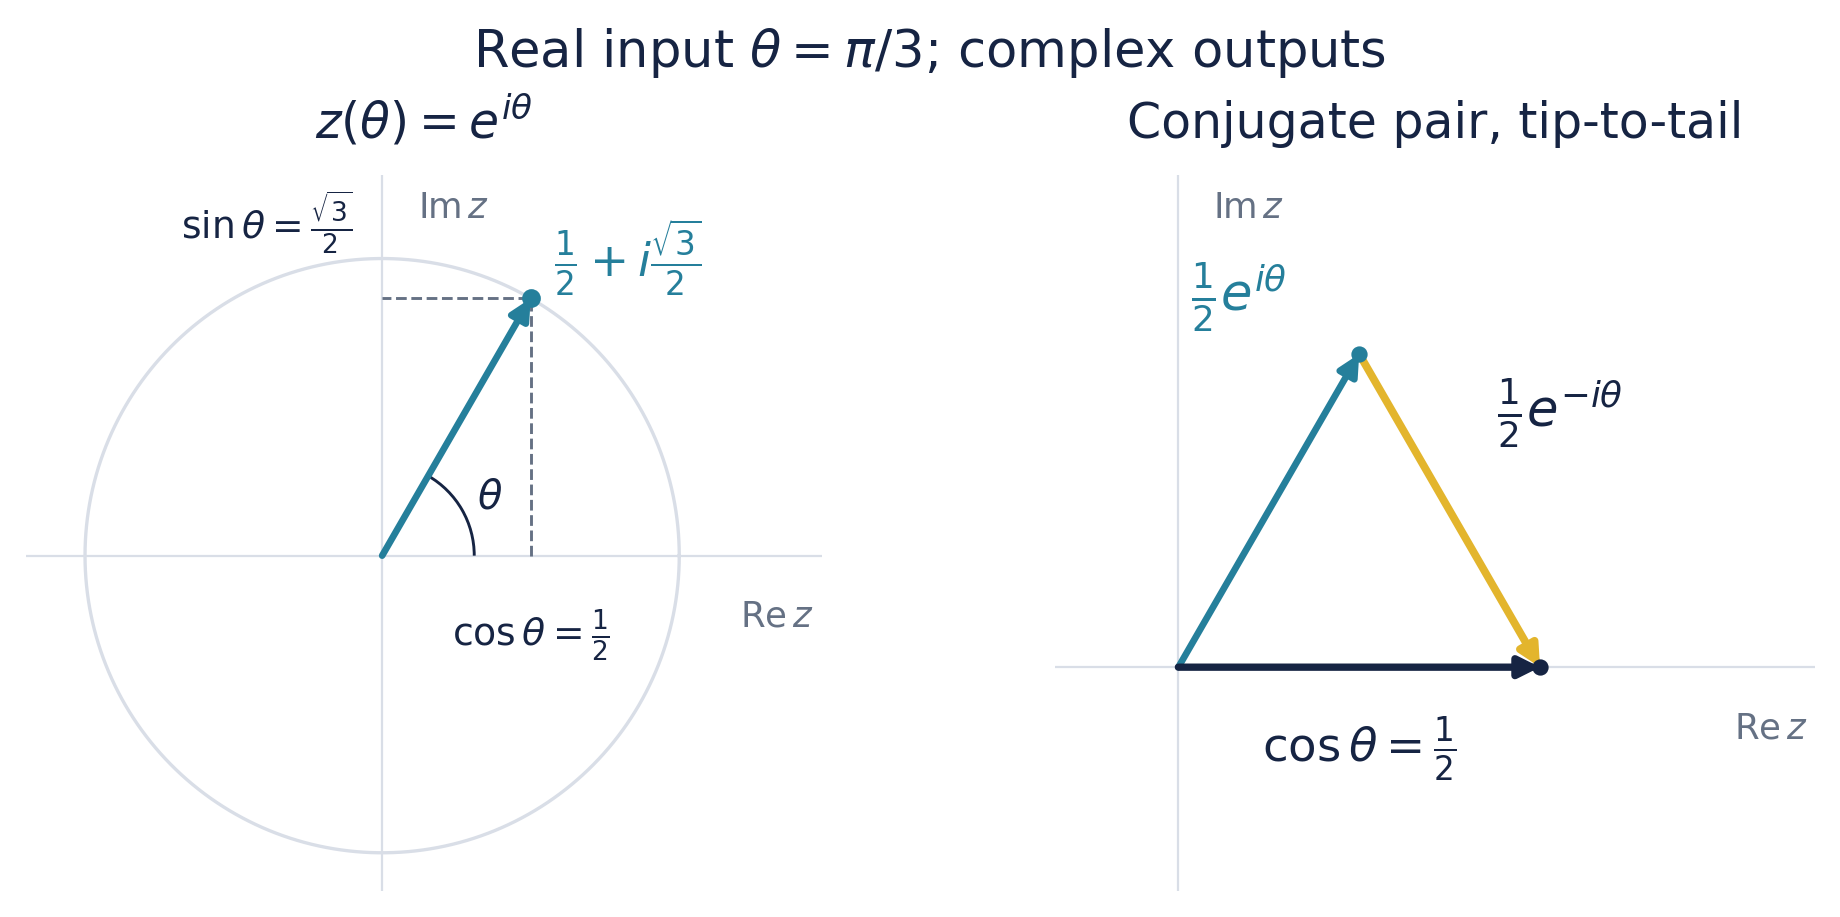

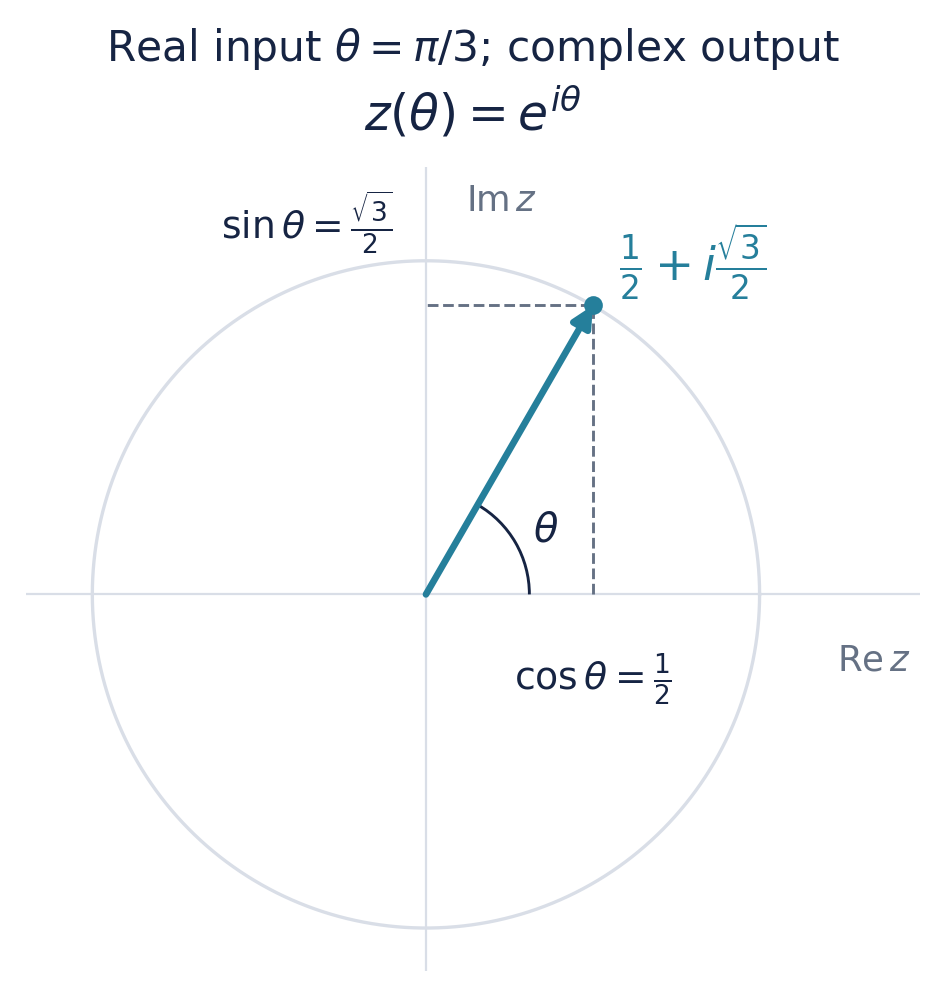

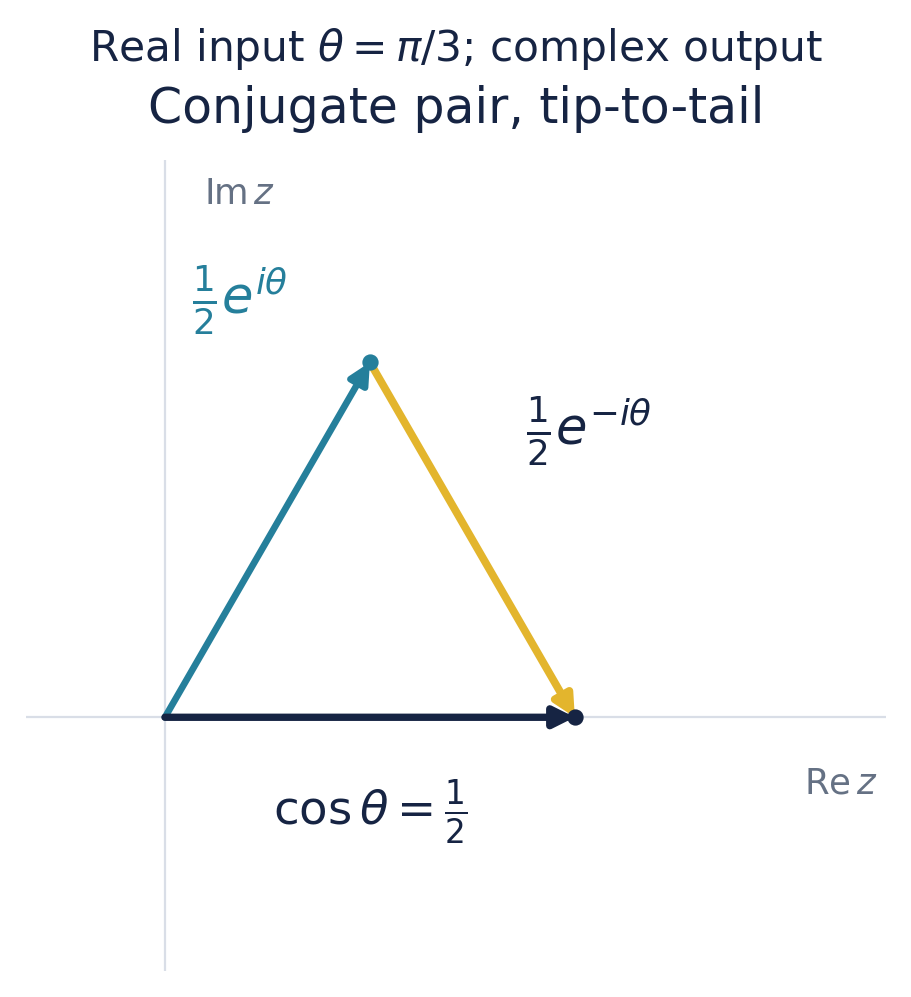

In [4]:
def draw_unit_circle_panel(ax):
    """Show one complex output at the real input theta=pi/3."""
    angle = PI / 3
    point = np.array([np.cos(angle), np.sin(angle)])
    circle = np.linspace(0, 2 * PI, 501)
    complex_plane(ax, (-1.2, 1.48), (-1.13, 1.28))
    ax.plot(np.cos(circle), np.sin(circle), color=GRID, linewidth=1.5)
    draw_vector(ax, (0, 0), point, TEAL)
    ax.plot(
        [point[0], point[0], 0], [0, point[1], point[1]],
        color=MUTED, linewidth=1.3, linestyle="--",
    )
    ax.scatter(*point, s=55, color=TEAL, zorder=6)
    ax.add_patch(Arc(
        (0, 0), 0.62, 0.62, theta1=0, theta2=60,
        color=NAVY, linewidth=1.3,
    ))
    ax.text(0.32, 0.16, r"$\theta$", fontsize=18)
    ax.text(
        0.58, 0.94, r"$\frac{1}{2}+i\frac{\sqrt{3}}{2}$",
        color=TEAL, fontsize=21,
    )
    ax.text(
        0.50, -0.17, r"$\cos\theta=\frac{1}{2}$",
        ha="center", va="top", fontsize=17,
    )
    ax.text(
        -0.10, 1.07,
        r"$\sin\theta=\frac{\sqrt{3}}{2}$",
        ha="right", fontsize=17,
    )
    ax.set_title(r"$z(\theta)=e^{i\theta}$", pad=17)


def draw_conjugate_pair_panel(ax):
    """Add the two conjugate half-vectors at theta=pi/3."""
    angle = PI / 3
    point = np.array([np.cos(angle), np.sin(angle)])
    complex_plane(ax, (-0.17, 0.88), (-0.31, 0.68))
    first = point / 2
    total = np.array([np.cos(angle), 0.0])
    draw_vector(ax, (0, 0), first, TEAL)
    draw_vector(ax, first, total, GOLD, linewidth=3.5)
    draw_vector(ax, (0, 0), total, NAVY, linewidth=3.3)
    ax.scatter(*first, s=40, color=TEAL, zorder=6)
    ax.scatter(*total, s=40, color=NAVY, zorder=6)
    ax.text(
        first[0] - 0.10, first[1] + 0.06,
        r"$\frac{1}{2}e^{i\theta}$", ha="right",
        color=TEAL, fontsize=23,
    )
    ax.text(
        first[0] + 0.19, first[1] - 0.10,
        r"$\frac{1}{2}e^{-i\theta}$", color=NAVY, fontsize=23,
    )
    ax.text(
        total[0] / 2, -0.13, r"$\cos\theta=\frac{1}{2}$",
        ha="center", fontsize=21,
    )
    ax.set_title("Conjugate pair, tip-to-tail", pad=17)


fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.5), layout="constrained")
draw_unit_circle_panel(axes[0])
draw_conjugate_pair_panel(axes[1])
fig.suptitle(r"Real input $\theta=\pi/3$; complex outputs", fontsize=23)
export_plot(fig, "02-complex-rotations")

for draw_panel, stem in (
    (draw_unit_circle_panel, "02a-unit-circle"),
    (draw_conjugate_pair_panel, "02b-conjugate-pair"),
):
    fig, ax = plt.subplots(figsize=(6.8, 6.0), layout="constrained")
    draw_panel(ax)
    fig.suptitle(
        r"Real input $\theta=\pi/3$; complex output", fontsize=19,
    )
    export_plot(fig, stem)


## 3. Freeze one frequency, then average

For the simple complex target
$f(\theta)=1+e^{i\theta}+e^{2i\theta}$, testing $m=1$ means multiplying
by $e^{-i\theta}$. The three terms become $e^{-i\theta}$, $1$, and
$e^{i\theta}$. Their continuous means are $0$, $1$, and $0$, so $C_1=1$.
The 12 points are sampled uniformly in $\theta$, not in arc length along
an arbitrary signal curve. For these modes, the discrete means also
equal the continuous means exactly, up to floating-point roundoff.


Saved 03-freeze-and-average.svg and 03-freeze-and-average.png


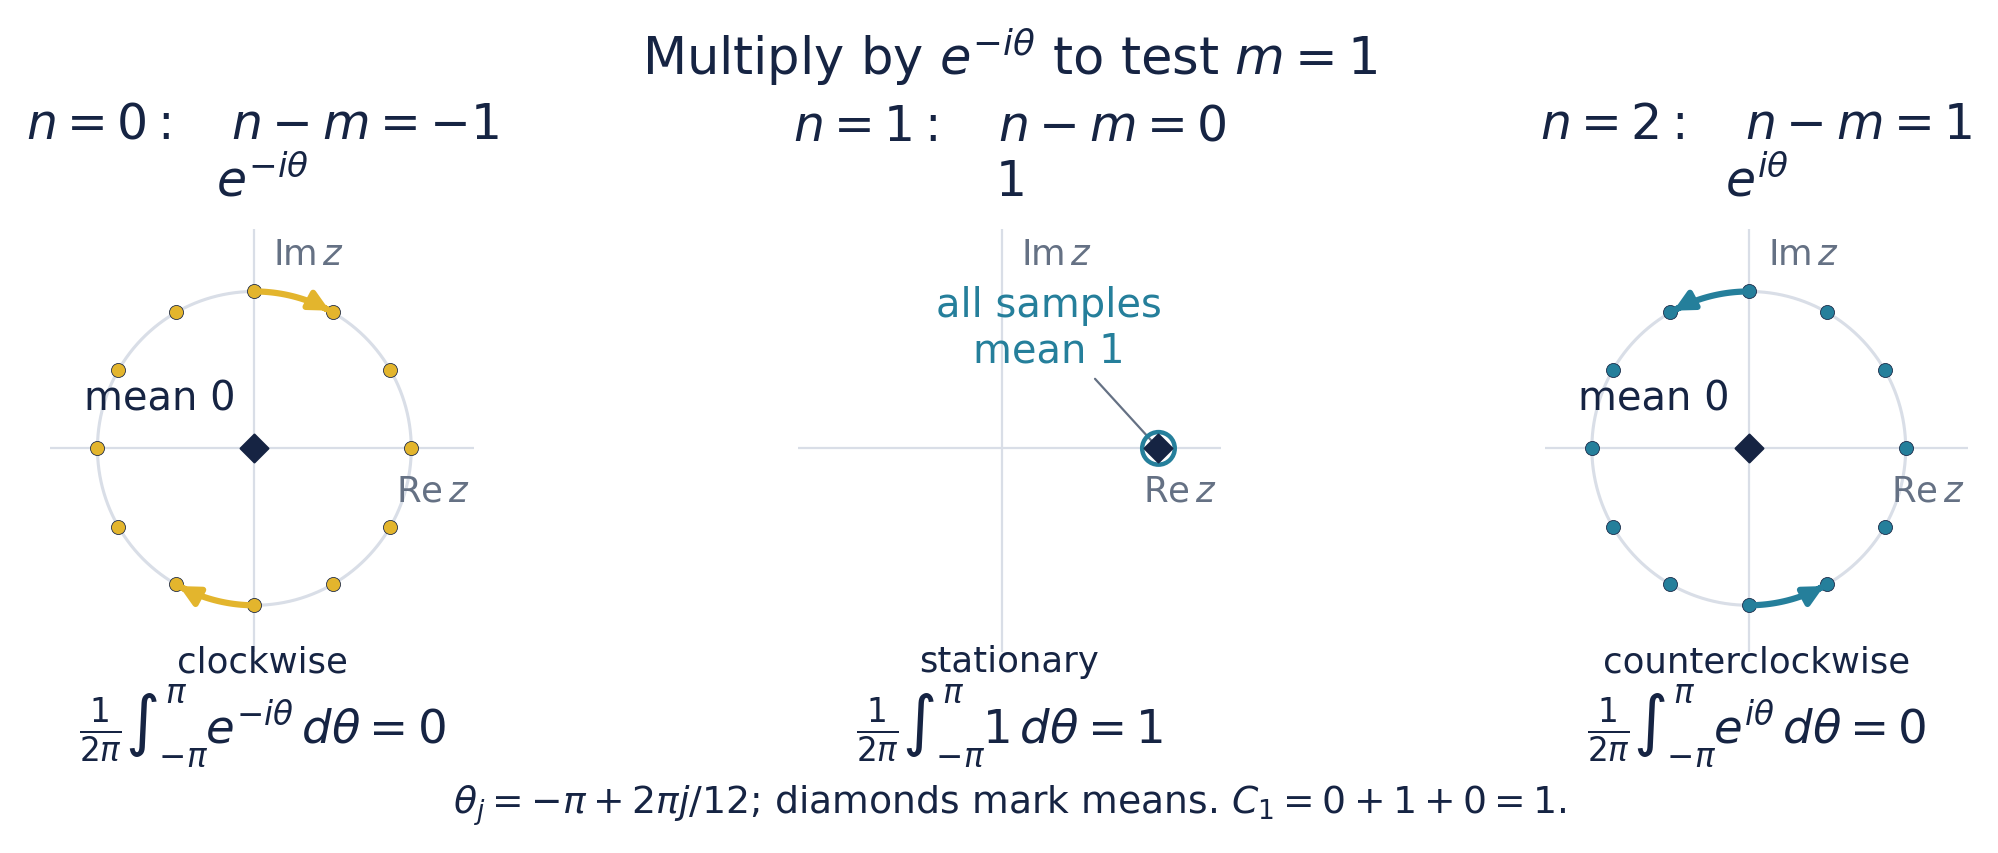

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14.0, 5.1), layout="constrained")
samples = -PI + 2 * PI * np.arange(12) / 12
circle = np.linspace(0, 2 * PI, 501)
cases = [
    (0, -1, GOLD, r"$e^{-i\theta}$", "clockwise", 0),
    (1, 0, TEAL, "$1$", "stationary", 1),
    (2, 1, TEAL, r"$e^{i\theta}$", "counterclockwise", 0),
]

for ax, (n, rate, color, term, motion, mean) in zip(axes, cases):
    complex_plane(ax)
    if rate:
        ax.plot(np.cos(circle), np.sin(circle), color=GRID, linewidth=1.4)
        values = np.exp(1j * rate * samples)
        ax.scatter(
            values.real, values.imag, s=40, color=color,
            edgecolor=NAVY, linewidth=0.35, zorder=3,
        )
        orbit_arrow(ax, PI / 2, rate, color)
        orbit_arrow(ax, 3 * PI / 2, rate, color)
        ax.scatter(0, 0, marker="D", s=78, color=NAVY, zorder=6)
        ax.text(-0.12, 0.25, "mean 0", ha="right", fontsize=18)
    else:
        ax.scatter(
            1, 0, s=215, facecolor="none", edgecolor=TEAL,
            linewidth=2, zorder=4,
        )
        ax.scatter(1, 0, marker="D", s=78, color=NAVY, zorder=6)
        ax.annotate(
            "all samples\nmean 1", xy=(1, 0), xytext=(0.3, 0.55),
            ha="center", color=TEAL, fontsize=18,
            arrowprops={"arrowstyle": "-", "color": MUTED},
        )
    ax.set_title(rf"$n={n}:\quad n-m={rate}$" + "\n" + term, pad=15)
    ax.text(
        0.5, -0.045, motion, ha="center", fontsize=16,
        transform=ax.transAxes,
    )
    ax.text(
        0.5, -0.21,
        rf"$\frac{{1}}{{2\pi}}\int_{{-\pi}}^{{\pi}}"
        rf"{term[1:-1]}\,d\theta={mean}$",
        transform=ax.transAxes, ha="center", fontsize=21,
    )

fig.suptitle(r"Multiply by $e^{-i\theta}$ to test $m=1$", fontsize=23)
fig.supxlabel(
    r"$\theta_j=-\pi+2\pi j/12$; diamonds mark means. $C_1=0+1+0=1$.",
    fontsize=17,
)
export_plot(fig, "03-freeze-and-average")


## 4. Reconstruct the periodic tent

\[
S_N(\theta)=\frac12+
\frac{4}{\pi^2}\sum_{\substack{1\leq n\leq N\\n\text{ odd}}}
\frac{\cos n\theta}{n^2}.
\]

Each partial sum is periodic. Its endpoint values agree, but they need
not be zero: periodic boundary conditions require matching endpoints,
not Dirichlet values. All three panels use identical axes.
The standalone `04a` target omits the partial sums for a prediction slide.


Saved 04-periodic-tent-reconstruction.svg and 04-periodic-tent-reconstruction.png
Saved 04a-tent-target.svg and 04a-tent-target.png


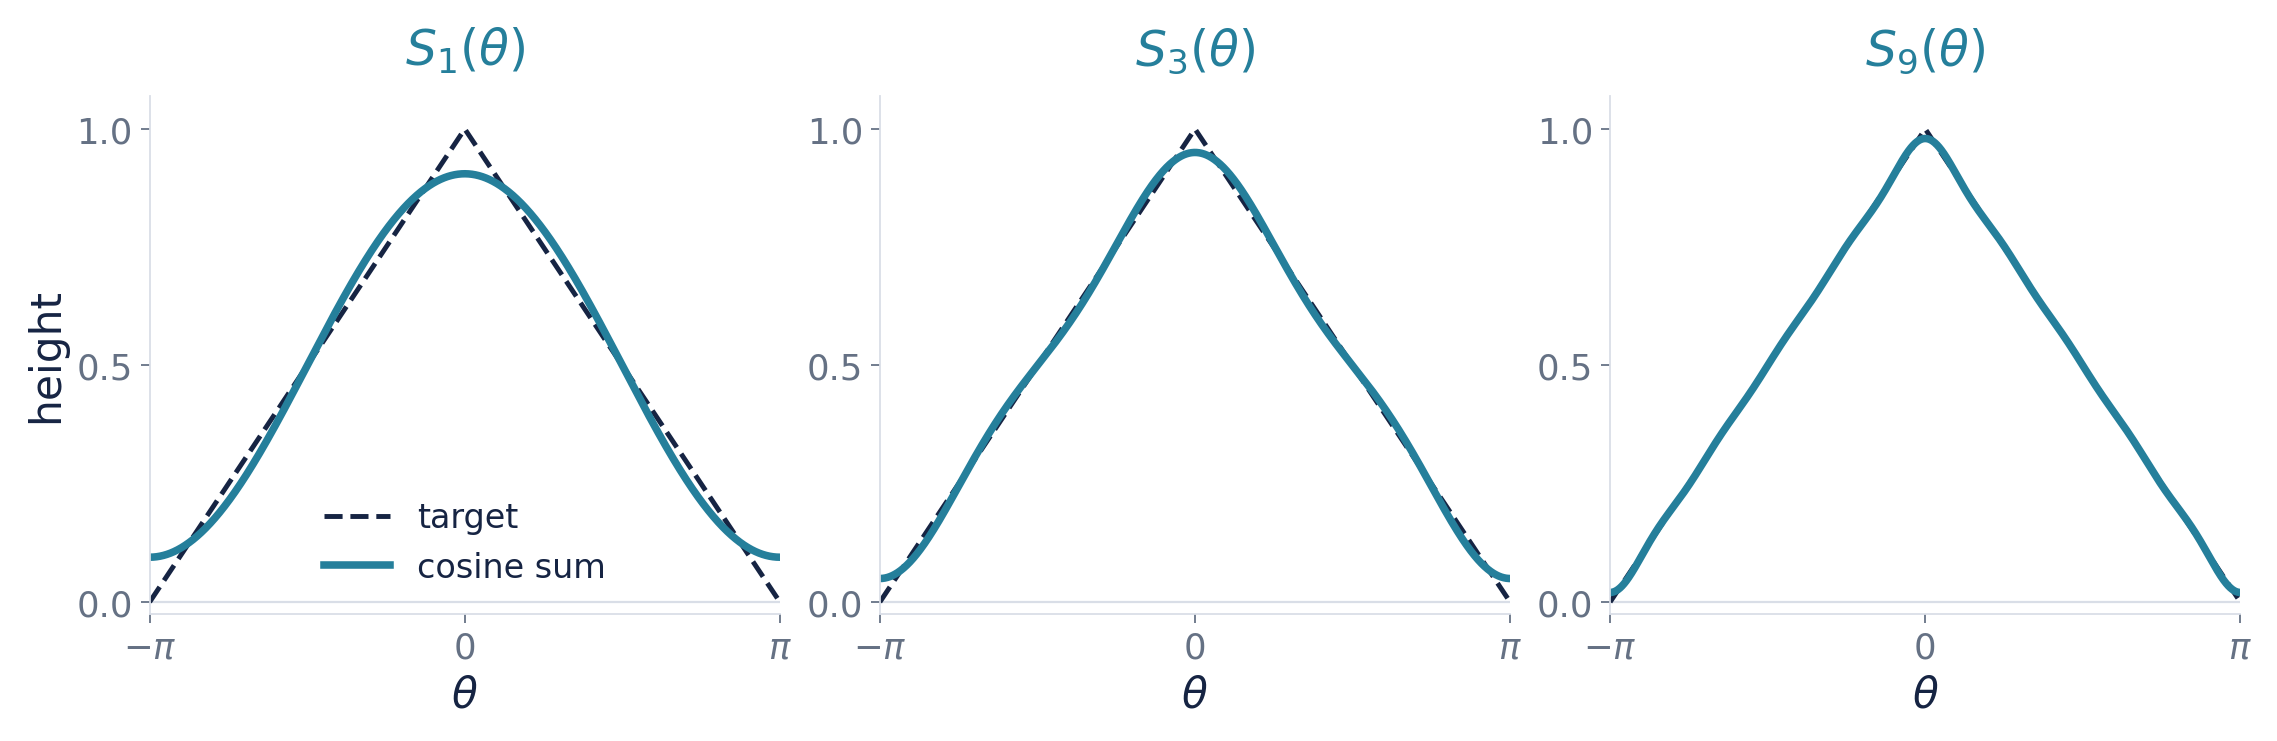

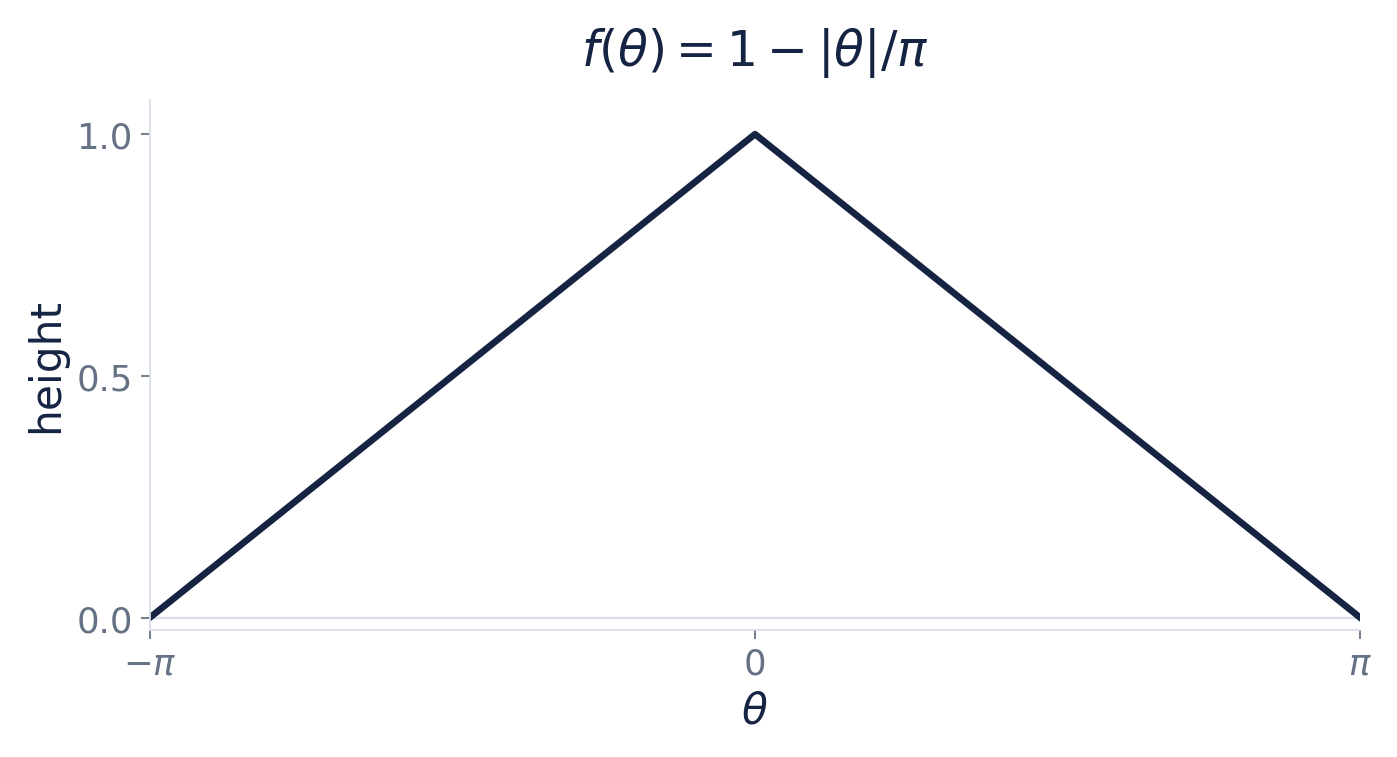

In [6]:
theta = np.linspace(-PI, PI, 2001)
fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.4), layout="constrained")

for ax, highest_mode in zip(axes, (1, 3, 9)):
    ax.plot(
        theta, periodic_tent(theta), color=NAVY,
        linestyle="--", linewidth=2.2, label="target",
    )
    ax.plot(
        theta, tent_partial_sum(theta, highest_mode),
        color=TEAL, linewidth=3.4, label="cosine sum",
    )
    periodic_axis(ax, ylim=(-0.025, 1.07))
    ax.set_yticks([0, 0.5, 1])
    ax.set_title(rf"$S_{{{highest_mode}}}(\theta)$", color=TEAL, pad=14)

axes[0].set_ylabel("height")
axes[0].legend(loc="lower center", fontsize=15)
export_plot(fig, "04-periodic-tent-reconstruction")

fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
ax.plot(theta, periodic_tent(theta), color=NAVY, linewidth=3.0)
periodic_axis(ax, ylim=(-0.025, 1.07))
ax.set_yticks([0, 0.5, 1])
ax.set_ylabel("height")
ax.set_title(r"$f(\theta)=1-|\theta|/\pi$", pad=16)
export_plot(fig, "04a-tent-target")


## 5. The periodic equation $u-u''=f$ filters the modes

For the normalized case $L=\pi$, the multiplier is
$G_n=1/(1+n^2)$. The zero mode passes unchanged, so the mean remains
$1/2$. The left panel uses 200 odd cosine modes; the uniform tail error
in $u$ is less than $4/(3\pi^2\cdot399^3)<2.2\times10^{-9}$.
The right panel shows the operator multiplier, not the forcing's
coefficient magnitudes.
For a general half-length $L$, the multiplier is
$1/(1+(n\pi/L)^2)$.


Saved 05-periodic-operator-filter.svg and 05-periodic-operator-filter.png


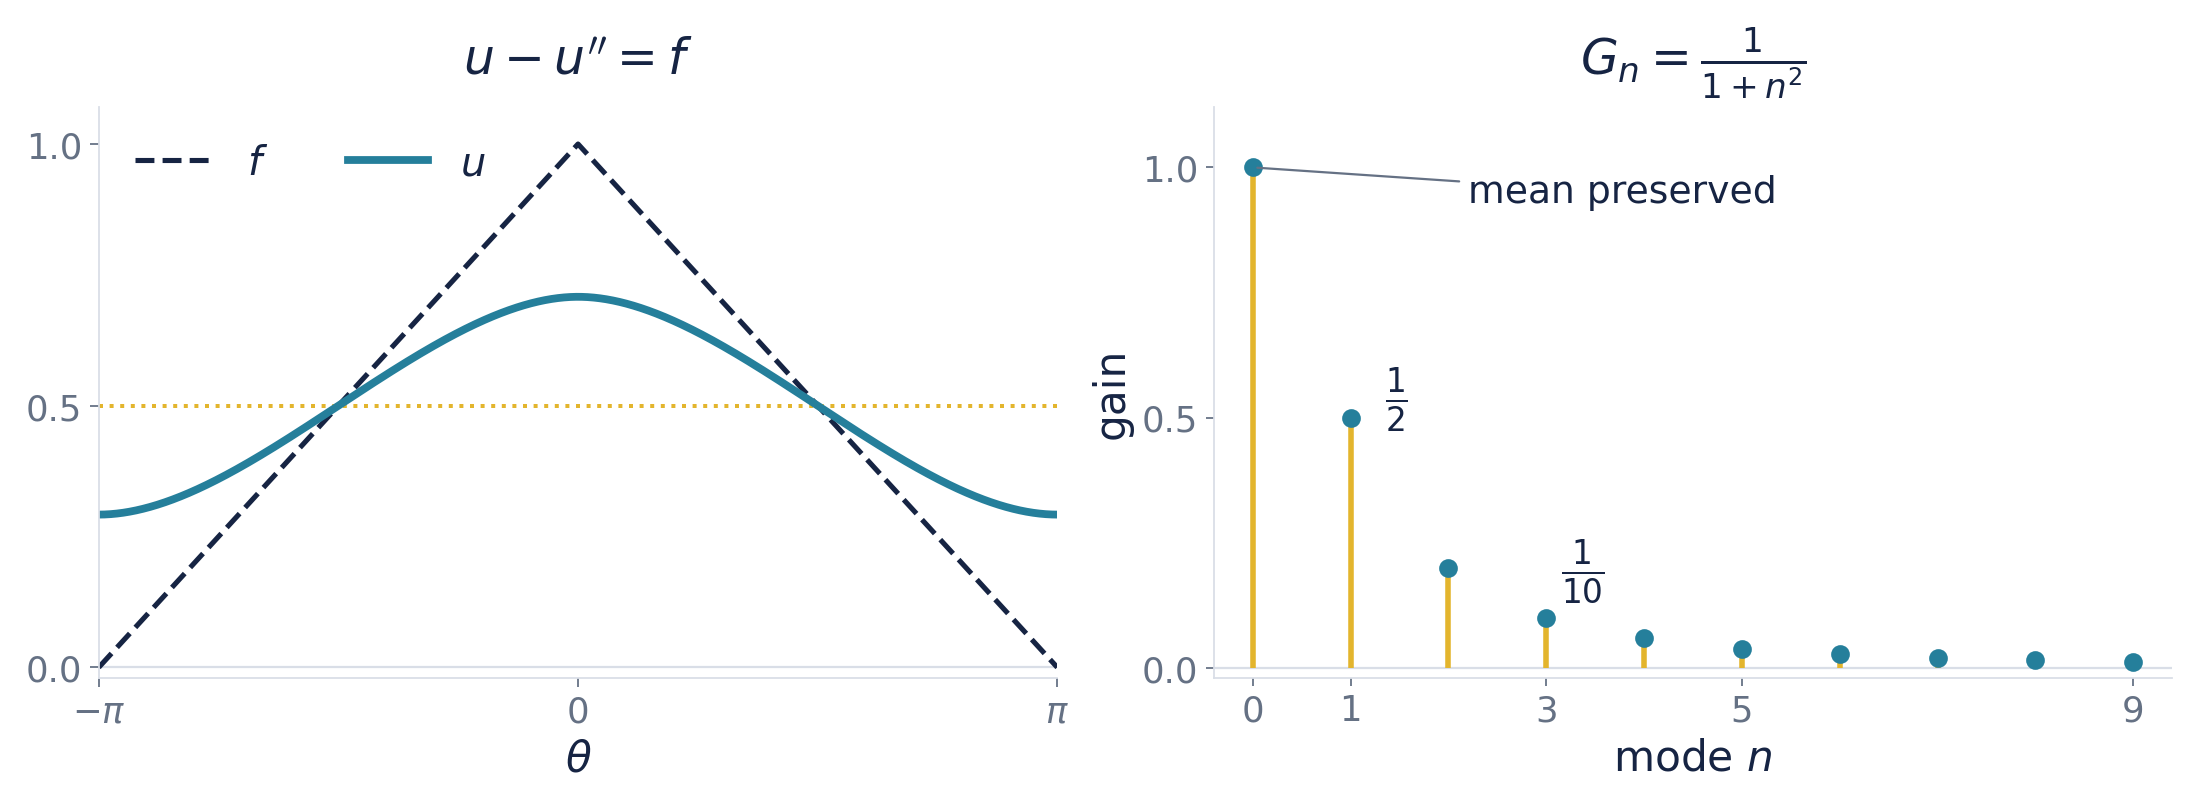

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), layout="constrained")
theta = np.linspace(-PI, PI, 2001)

ax = axes[0]
ax.plot(
    theta, periodic_tent(theta), color=NAVY, linestyle="--",
    linewidth=2.3, label="$f$",
)
ax.plot(
    theta, filtered_tent(theta, highest_mode=399),
    color=TEAL, linewidth=3.5, label="$u$",
)
ax.axhline(0.5, color=GOLD, linewidth=1.8, linestyle=":", zorder=0)
periodic_axis(ax, ylim=(-0.02, 1.07))
ax.set_yticks([0, 0.5, 1])
ax.set_title(r"$u-u''=f$", pad=15)
ax.legend(loc="upper left", ncol=2, fontsize=18)

ax = axes[1]
modes = np.arange(10)
gain = 1 / (1 + modes**2)
ax.vlines(modes, 0, gain, color=GOLD, linewidth=2.5)
ax.scatter(modes, gain, s=55, color=TEAL, zorder=3)
ax.axhline(0, color=GRID, linewidth=1, zorder=0)
ax.set_xlim(-0.4, 9.4)
ax.set_ylim(-0.02, 1.12)
ax.set_xticks([0, 1, 3, 5, 9])
ax.set_yticks([0, 0.5, 1])
ax.set_xlabel("mode $n$")
ax.set_ylabel("gain")
ax.set_title(r"$G_n=\frac{1}{1+n^2}$", pad=15)
ax.annotate(
    "mean preserved", xy=(0, 1), xytext=(2.2, 0.93), fontsize=17,
    arrowprops={"arrowstyle": "-", "color": MUTED},
)
ax.text(1.35, 0.51, r"$\frac{1}{2}$", fontsize=21)
ax.text(3.15, 0.17, r"$\frac{1}{10}$", fontsize=21)
export_plot(fig, "05-periodic-operator-filter")


## 6. Optional bridge: heat decay

For $u_t=u_{\theta\theta}$, one spatial mode has amplitude
$A_n(t)=A_n(0)e^{-n^2t}$. With equal initial amplitudes, the third mode
has nine times the decay rate; there is no fixed amplitude ratio of
one ninth. The plot uses diffusivity $\kappa=1$.


Saved 06-heat-decay.svg and 06-heat-decay.png


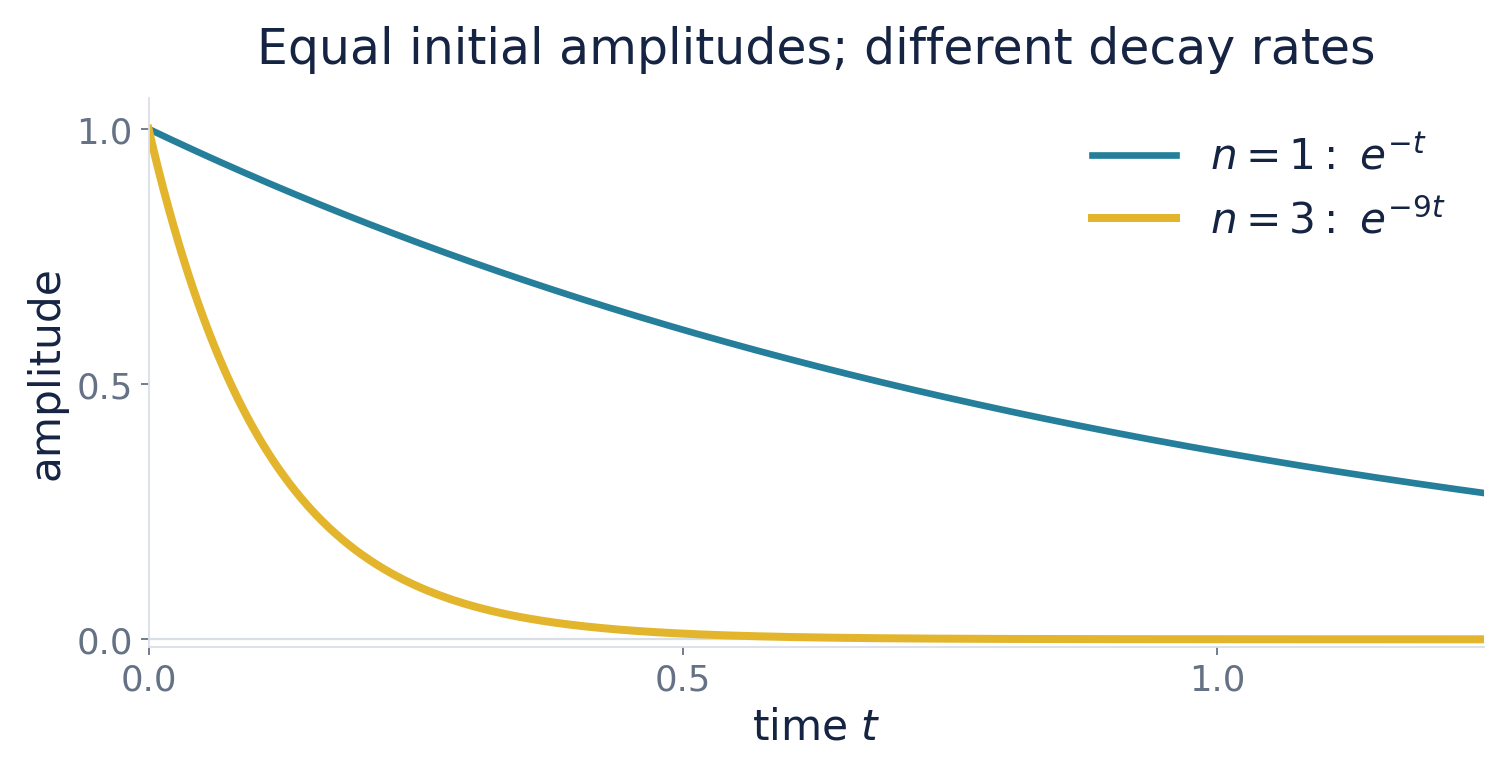

In [8]:
time = np.linspace(0, 1.25, 801)
fig, ax = plt.subplots(figsize=(9.2, 4.6), layout="constrained")
ax.plot(time, np.exp(-time), color=TEAL, label=r"$n=1:\ e^{-t}$")
ax.plot(
    time, np.exp(-9 * time), color=GOLD,
    linewidth=3.6, label=r"$n=3:\ e^{-9t}$",
)
ax.axhline(0, color=GRID, linewidth=1, zorder=0)
ax.set_xlim(0, 1.25)
ax.set_ylim(-0.015, 1.06)
ax.set_xticks([0, 0.5, 1])
ax.set_yticks([0, 0.5, 1])
ax.set_xlabel("time $t$")
ax.set_ylabel("amplitude")
ax.legend(loc="upper right", fontsize=19)
ax.set_title("Equal initial amplitudes; different decay rates", pad=16)
export_plot(fig, "06-heat-decay")


## 7. Optional preview: separate the copies, fill the frequency axis

Use the compact triangular pulse $g(x)=\max(1-|x|,0)$ and repeat it
with period $T>2$. The fixed time window below shows copies leaving
view as $T$ grows. In frequency space,

\[
\omega_n=\frac{2\pi n}{T},\qquad
C_n^{(T)}=\frac{\widehat g(\omega_n)}{T},\qquad
\widehat g(\omega)=
\left(\frac{\sin(\omega/2)}{\omega/2}\right)^2.
\]

The displayed heights are **$TC_n^{(T)}$**, not the shrinking raw
coefficients. The continuous curve is the exact transform, with
$\widehat g(0)=1$. The grid spacing is $\Delta\omega=2\pi/T$.

This is the scaling behind
$\sum_n C_n^{(T)}e^{i\omega_nx}
=(2\pi)^{-1}\sum_n\widehat g(\omega_n)e^{i\omega_nx}\Delta\omega$.


Saved 07-fourier-transform-preview.svg and 07-fourier-transform-preview.png


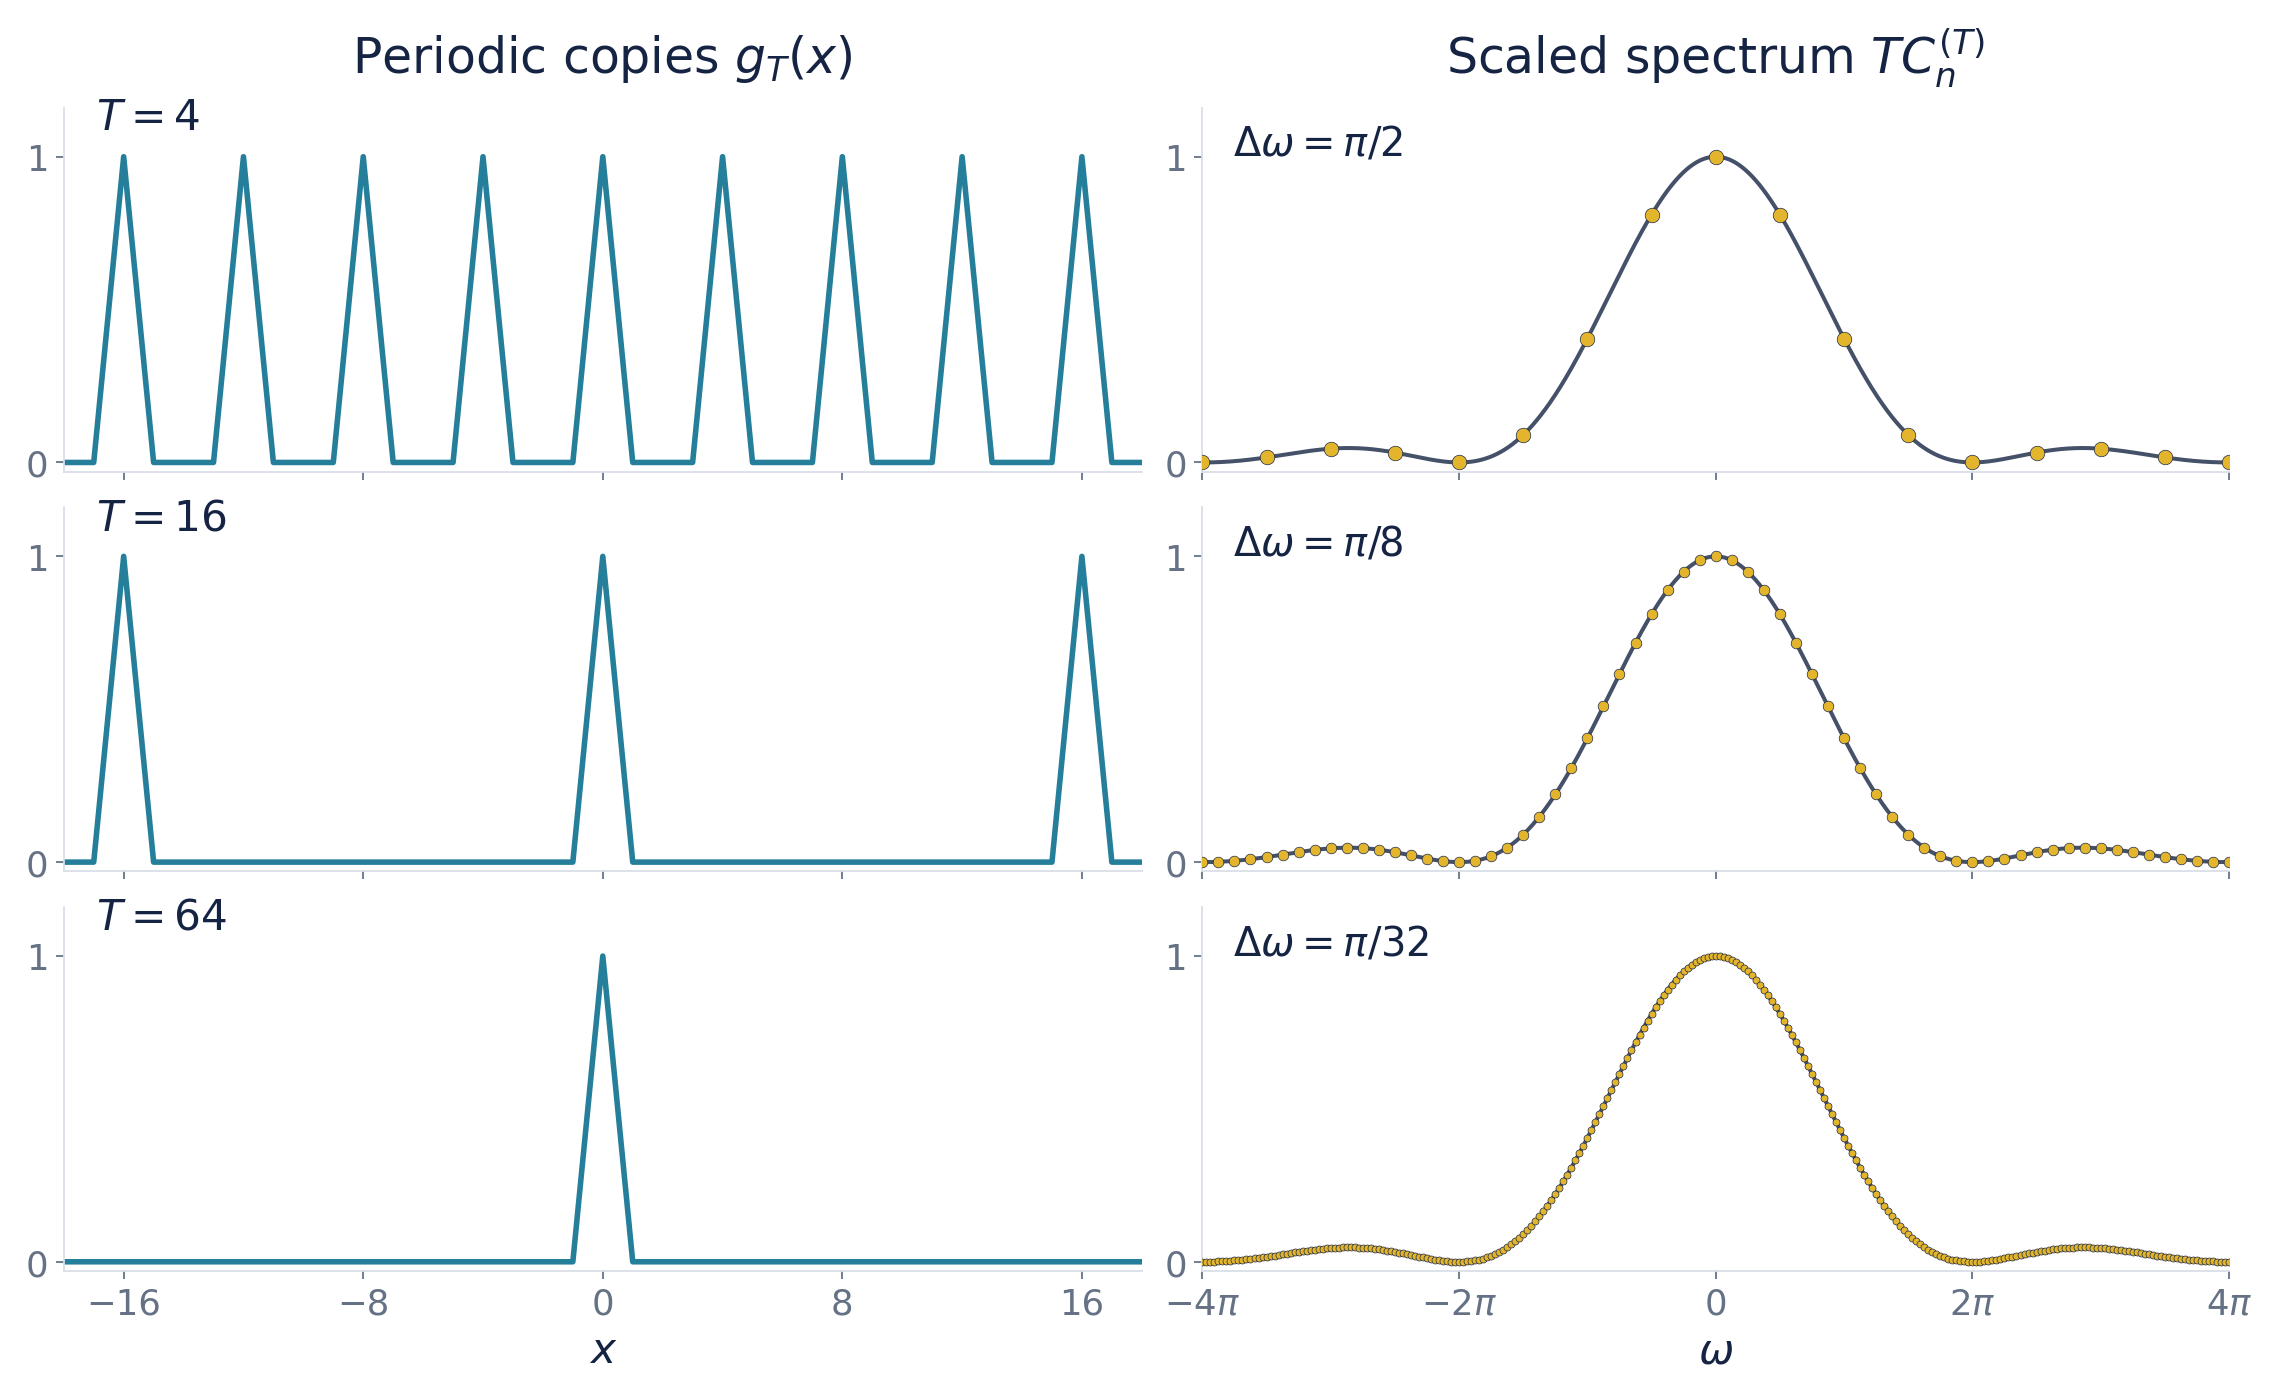

In [9]:
fig, axes = plt.subplots(
    3, 2, figsize=(14.0, 8.5), layout="constrained",
    gridspec_kw={"width_ratios": [1.05, 1]},
)
space = np.linspace(-18, 18, 9001)
frequencies = np.linspace(-4 * PI, 4 * PI, 1601)
periods = (4, 16, 64)
spacing_labels = (r"$\pi/2$", r"$\pi/8$", r"$\pi/32$")

for row, (period, spacing_label) in enumerate(zip(periods, spacing_labels)):
    ax = axes[row, 0]
    ax.plot(space, repeated_pulse(space, period), color=TEAL, linewidth=2.5)
    ax.set_xlim(-18, 18)
    ax.set_ylim(-0.03, 1.16)
    ax.set_xticks([-16, -8, 0, 8, 16])
    ax.set_yticks([0, 1])
    ax.text(
        0.03, 0.94, rf"$T={period}$", transform=ax.transAxes,
        fontsize=19, bbox={"facecolor": "white", "edgecolor": "none"},
    )
    if row == 0:
        ax.set_title(r"Periodic copies $g_T(x)$", pad=16)
    if row < 2:
        ax.set_xticklabels([])
    else:
        ax.set_xlabel("$x$")

    ax = axes[row, 1]
    ax.plot(
        frequencies, pulse_transform(frequencies),
        color=NAVY, linewidth=1.8, alpha=0.8,
    )
    step = 2 * PI / period
    indices = np.arange(-2 * period, 2 * period + 1)
    sample_frequencies = indices * step
    scaled_coefficients = pulse_transform(sample_frequencies)
    point_size = (43, 23, 10)[row]
    ax.scatter(
        sample_frequencies, scaled_coefficients, color=GOLD,
        edgecolor=NAVY, linewidth=0.3, s=point_size, zorder=3,
    )
    ax.set_xlim(-4 * PI, 4 * PI)
    ax.set_ylim(-0.03, 1.16)
    ax.set_xticks(
        [-4 * PI, -2 * PI, 0, 2 * PI, 4 * PI],
        [r"$-4\pi$", r"$-2\pi$", "0", r"$2\pi$", r"$4\pi$"],
    )
    ax.set_yticks([0, 1])
    ax.text(
        0.03, 0.87, r"$\Delta\omega=$" + spacing_label,
        transform=ax.transAxes, fontsize=18,
    )
    if row == 0:
        ax.set_title(r"Scaled spectrum $TC_n^{(T)}$", pad=16)
    if row < 2:
        ax.set_xticklabels([])
    else:
        ax.set_xlabel(r"$\omega$")

export_plot(fig, "07-fourier-transform-preview")


## Numerical sanity checks

The following checks independently integrate the Fourier coefficients and
the pulse transform, verify the rotation averages, and test the finite
operator identity. Assertions use tolerances appropriate to double
precision; no empirical or external data are used.


In [10]:
endpoint_errors = []
for n in (1, 2):
    endpoint_errors.extend([
        abs(np.cos(-n * PI) - np.cos(n * PI)),
        abs(np.sin(-n * PI) - np.sin(n * PI)),
        abs(-n * np.sin(-n * PI) + n * np.sin(n * PI)),
        abs(n * np.cos(-n * PI) - n * np.cos(n * PI)),
    ])
assert max(endpoint_errors) < 1e-13

angle = PI / 3
conjugate_sum = 0.5 * np.exp(1j * angle) + 0.5 * np.exp(-1j * angle)
assert abs(conjugate_sum - np.cos(angle)) < 1e-14
sample_means = np.array([
    np.mean(np.exp(1j * rate * samples)) for rate in (-1, 0, 1)
])
assert np.max(np.abs(sample_means - [0, 1, 0])) < 1e-14

measured_mean = quad(
    lambda x: float(periodic_tent(x)), -PI, PI, points=[0],
)[0] / (2 * PI)
coefficient_errors = []
for n in range(1, 11):
    measured_cosine = quad(
        lambda x: float(periodic_tent(x)) * np.cos(n * x),
        -PI, PI, points=[0], epsabs=1e-12,
    )[0] / PI
    measured_sine = quad(
        lambda x: float(periodic_tent(x)) * np.sin(n * x),
        -PI, PI, points=[0], epsabs=1e-12,
    )[0] / PI
    coefficient_errors.extend([
        abs(measured_cosine - cosine_coefficient(n)),
        abs(measured_sine),
    ])
assert abs(measured_mean - 0.5) < 1e-14
assert max(coefficient_errors) < 1e-12

check_grid = np.linspace(-PI, PI, 1501)
highest_mode = 99
finite_residual = (
    filtered_tent(check_grid, highest_mode)
    - filtered_tent(check_grid, highest_mode, derivative=2)
    - tent_partial_sum(check_grid, highest_mode)
)
assert np.max(np.abs(finite_residual)) < 1e-12
filter_endpoints = filtered_tent(np.array([-PI, PI]), 399)
filter_slopes = filtered_tent(
    np.array([-PI, PI]), 399, derivative=1,
)
assert abs(filter_endpoints[0] - filter_endpoints[1]) < 1e-13
assert abs(filter_slopes[0] - filter_slopes[1]) < 1e-13

test_f = 2 + 3 * np.cos(check_grid) + 4 * np.sin(2 * check_grid)
test_u = 2 + 1.5 * np.cos(check_grid) + 0.8 * np.sin(2 * check_grid)
test_u_dd = -1.5 * np.cos(check_grid) - 3.2 * np.sin(2 * check_grid)
assert np.max(np.abs(test_u - test_u_dd - test_f)) < 1e-13

transform_errors = []
for omega in (0, 0.5, PI, 2 * PI, 3 * PI):
    measured_transform = 2 * quad(
        lambda x: (1 - x) * np.cos(omega * x), 0, 1,
        epsabs=1e-12,
    )[0]
    transform_errors.append(abs(measured_transform - pulse_transform(omega)))
assert max(transform_errors) < 1e-12

scaling_errors = []
for period in (4, 16, 64):
    for n in (0, 1, 3, 7):
        omega = 2 * PI * n / period
        coefficient = 2 * quad(
            lambda x: (1 - x) * np.cos(omega * x), 0, 1,
        )[0] / period
        scaling_errors.append(
            abs(period * coefficient - pulse_transform(omega))
        )
assert max(scaling_errors) < 1e-12
assert abs(np.exp(-9 * (1 / 9)) - np.exp(-1)) < 1e-15

print(f"Endpoint value/slope error: {max(endpoint_errors):.2e}")
print("Rotation means:", np.round(sample_means.real, 12))
print(f"Tent mean: {measured_mean:.12f}")
print(f"Tent coefficient error: {max(coefficient_errors):.2e}")
print(f"Finite operator residual: {np.max(np.abs(finite_residual)):.2e}")
print(f"Pulse-transform error: {max(transform_errors):.2e}")
print(f"Scaled-coefficient error: {max(scaling_errors):.2e}")
print("All mathematical sanity checks passed.")
print("SVG exports:")
for svg_path, _ in CREATED_PLOTS:
    print(" -", svg_path.name)


Endpoint value/slope error: 9.80e-16
Rotation means: [0. 1. 0.]
Tent mean: 0.500000000000
Tent coefficient error: 1.07e-16
Finite operator residual: 9.99e-16
Pulse-transform error: 2.22e-16
Scaled-coefficient error: 2.22e-16
All mathematical sanity checks passed.
SVG exports:
 - 01-periodic-modes.svg
 - 02-complex-rotations.svg
 - 02a-unit-circle.svg
 - 02b-conjugate-pair.svg
 - 03-freeze-and-average.svg
 - 04-periodic-tent-reconstruction.svg
 - 04a-tent-target.svg
 - 05-periodic-operator-filter.svg
 - 06-heat-decay.svg
 - 07-fourier-transform-preview.svg
